<a href="https://colab.research.google.com/github/harigovindankjhari-afk/AI-DATASCIENCE_PORTFOLIO/blob/main/Time_series_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller

In [4]:
data=[100,110,120,130,150,170,180,200]
series=pd.Series(data)

In [5]:
series

,0
0,100
1,110
2,120
3,130
4,150
5,170
6,180
7,200


In [9]:
result=adfuller(series)

/tmp/ipykernel_601/802428715.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result=adfuller(series)


In [10]:
print("ADP STATISTIC:",result[0])
print("P-VALUE",result[1])

ADP STATISTIC: 2.645751311064594
P-VALUE 0.9990822226084852


In [11]:
diff_series=series.diff().dropna()
diff_series

,0
1,10.0
2,10.0
3,10.0
4,20.0
5,20.0
6,10.0
7,20.0


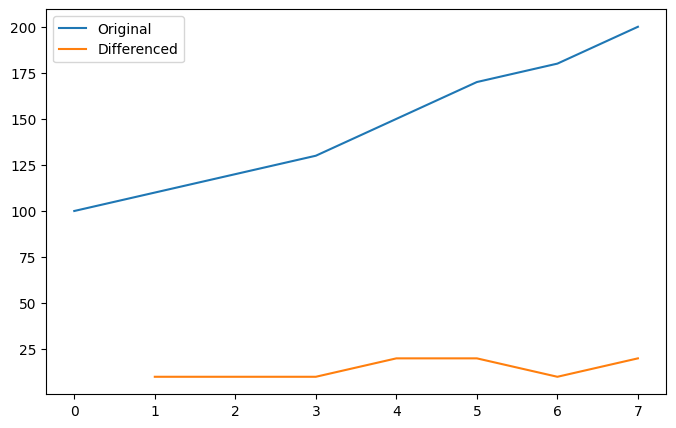

In [36]:
plt.figure(figsize=(8,5))
plt.plot(series,label='Original')
plt.plot(diff_series,label="Differenced")
plt.legend()
plt.show()


In [22]:
model=ARIMA(series,order=(1,1,1))
model_fit=model.fit()

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params


In [23]:
print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                    8
Model:                 ARIMA(1, 1, 1)   Log Likelihood                 -23.467
Date:                Mon, 02 Nov 2026   AIC                             52.935
Time:                        20:47:29   BIC                             52.772
Sample:                             0   HQIC                            50.929
                                  - 8                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9870      0.081     12.154      0.000       0.828       1.146
ma.L1         -0.6111      0.577     -1.059      0.290      -1.742       0.520
sigma2        34.5500     36.131      0.956      0.3

In [30]:
#predicted values

In [32]:
forecast=model_fit.forecast(steps=5)
print("FORECAST:",forecast)

FORECAST: 8     215.723479
9     231.242728
10    246.560400
11    261.679112
12    276.601450
Name: predicted_mean, dtype: float64


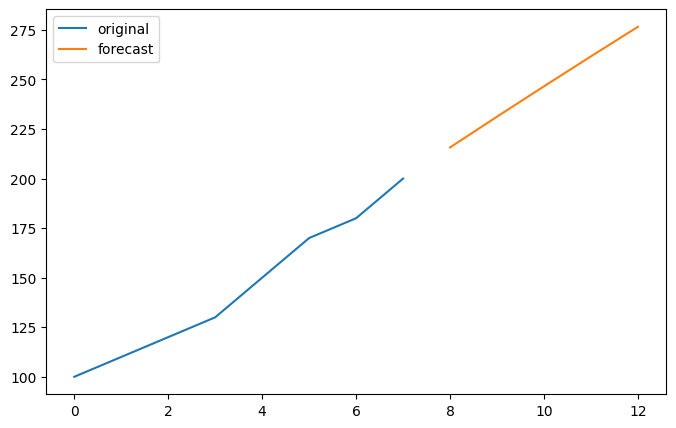

In [35]:
plt.figure(figsize=(8,5))
plt.plot(series,label='original')
plt.plot(forecast,label='forecast')
plt.legend()
plt.show()